# Exploratory analysis: what goes with customer churn?

**Scope.** Only the 5,634 *training* rows are used; the 1,409 test rows stay untouched, so nothing seen here can steer a choice that the test set is supposed to judge. The helpers live in `mlproject.eda` and are unit-tested, so every number in the text below is computed, not typed in.

**What this notebook can and cannot say.** The data is a snapshot of one (sample) telecom. Everything here is an *association* between a column and churn. A pattern may reflect price, service quality, customer type or just who happens to sign which contract, and the notebook checks the main alternative explanations rather than assuming one.

In [1]:
import matplotlib.pyplot as plt

from mlproject import eda
from mlproject.data import TARGET, load
from mlproject.split import split

train, _ = split(load())  # the second value is the held-out test set; it is deliberately never used here
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ACCENT, GREY = "#c44e52", "#8c8c8c"

print(f"{len(train):,} customers, {train[TARGET].mean():.1%} churned")
print("missing values:", eda.missing_summary(train).to_dict()["missing"])

5,634 customers, 26.5% churned
missing values: {'TotalCharges': 8}


## 1. The target

About 1 in 4 customers churned (26.5%), so a model that predicts "stays" for everyone is right 73.5% of the time. That is why the project scores models by PR-AUC rather than accuracy. The only missing values are the 8 brand-new customers in these rows (11 in the full file) with a blank `TotalCharges` and tenure 0; they are handled later inside the model pipeline.

## 2. The big three: contract, internet service, payment method

Each bar is a churn rate with a 95% Wilson interval (the interval is narrow here because every group has hundreds of customers).

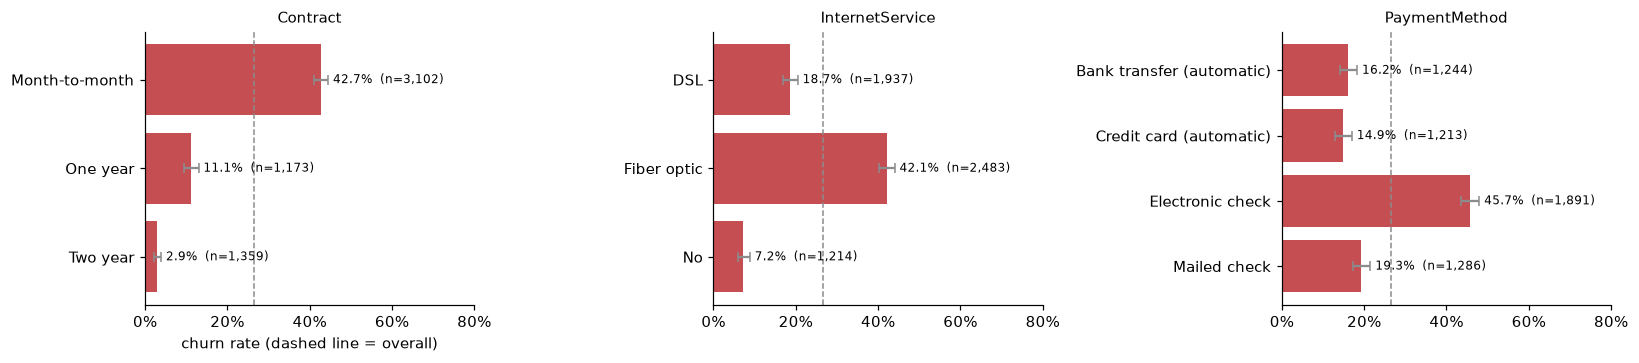

In [2]:
def bar_panel(ax, table, title):
    ax.barh(table.index.astype(str), table["rate"], color=ACCENT, xerr=[table["rate"] - table["lo"], table["hi"] - table["rate"]], ecolor=GREY, capsize=3)
    ax.axvline(train[TARGET].mean(), color=GREY, linestyle="--", linewidth=1)
    for y, (hi, rate, n) in enumerate(zip(table["hi"], table["rate"], table["n"])):
        ax.text(hi + 0.012, y, f"{rate:.1%}  (n={n:,})", va="center", fontsize=8)
    ax.invert_yaxis()  # same top-to-bottom order as the table
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 0.8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"], strict=True):
    bar_panel(ax, eda.rate_table(train, col), col)
axes[0].set_xlabel("churn rate (dashed line = overall)")
fig.tight_layout()
plt.show()

- **Contract:** month-to-month customers churn at 42.7%, one-year at 11.1%, two-year at 2.9%. It is the single strongest feature (see section 6).
- **Internet service:** fibre customers churn at 42.1%, DSL at 18.7%, and customers with no internet at 7.2%.
- **Payment method:** electronic-check customers churn at 45.7%; the other three methods sit between 14.9% and 19.3%.

These three overlap heavily (fibre customers are more often on month-to-month contracts, and so are electronic-check users), so section 4 tests whether each survives once the others are held fixed.

## 3. Tenure: the risk is front-loaded

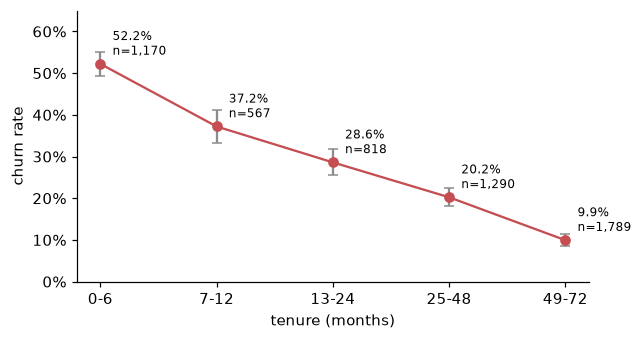

20.8% of customers have tenure <= 6 months, but they are 40.9% of all churners.
55.0% of all churners left within their first 12 months.
churned
stayed     38.0
churned    10.0


In [3]:
tenure = eda.rate_table(train, "tenure", eda.TENURE_BINS, eda.TENURE_LABELS)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(tenure.index.astype(str), tenure["rate"], yerr=[tenure["rate"] - tenure["lo"], tenure["hi"] - tenure["rate"]], marker="o", color=ACCENT, ecolor=GREY, capsize=3)
for x, (rate, n) in enumerate(zip(tenure["rate"], tenure["n"])):
    ax.annotate(f"{rate:.1%}\nn={n:,}", (x, rate), textcoords="offset points", xytext=(8, 6), fontsize=8)
ax.set_xlabel("tenure (months)")
ax.set_ylabel("churn rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, 0.65)
plt.show()

first_half_year = train[train["tenure"] <= 6]
within_year = train[train["tenure"] <= 12]
print(f"{len(first_half_year) / len(train):.1%} of customers have tenure <= 6 months, but they are "
      f"{first_half_year[TARGET].sum() / train[TARGET].sum():.1%} of all churners.")
print(f"{within_year[TARGET].sum() / train[TARGET].sum():.1%} of all churners left within their first 12 months.")
print(train.groupby(TARGET)["tenure"].median().rename({0: "stayed", 1: "churned"}).to_string())

Churn falls steadily with tenure, from 52.2% among customers in their first six months to 9.9% among those past four years. The six-month group is 20.8% of customers but 40.9% of churners, and 55.0% of all churners left within their first year. The median churned customer had a tenure of 10 months, against 38 for customers who stayed.

**Caveat from the data card:** `tenure` for a churned customer is how long they stayed, so part of this pattern is built into how the data was collected. A model using it is describing the snapshot, not scoring customers before they decide. The modelling stage measures how much the model leans on it.

## 4. Are those patterns real, or one pattern in disguise?

### 4a. Fibre against contract type

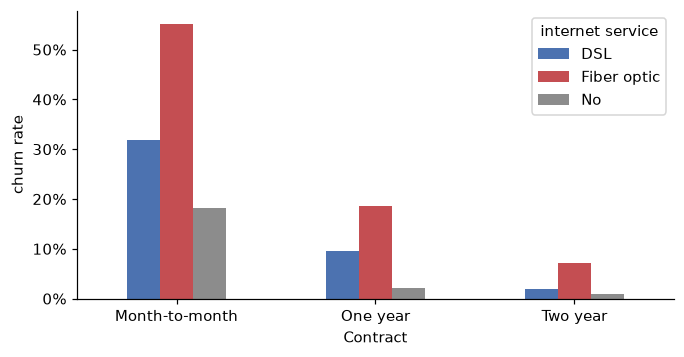

InternetService  DSL  Fiber optic   No
Contract                              
Month-to-month   973         1707  422
One year         452          436  285
Two year         512          340  507

share of each service on month-to-month: {'DSL': 0.502, 'Fiber optic': 0.687, 'No': 0.348}


In [4]:
rate, size = eda.stratified_rates(train, "Contract", "InternetService")
ax = (rate[["DSL", "Fiber optic", "No"]]).plot.bar(figsize=(7, 3.4), color=["#4c72b0", ACCENT, GREY], rot=0)
ax.set_ylabel("churn rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(title="internet service")
plt.show()
print(size.to_string())
print()
print("share of each service on month-to-month:", (train.groupby("InternetService")["Contract"].apply(lambda s: (s == "Month-to-month").mean())).round(3).to_dict())

Fibre customers do sign month-to-month contracts more often (68.7% against 50.2% for DSL), but the fibre gap does not disappear within any contract type: 55.1% against 31.8% on month-to-month, 18.6% against 9.5% on one-year, 7.1% against 2.0% on two-year. So fibre is associated with extra churn that contract type alone does not explain. The data cannot say *why* (price, reliability, competition), only that it is not a contract artefact.

### 4b. Monthly charges: price, or service type in disguise?

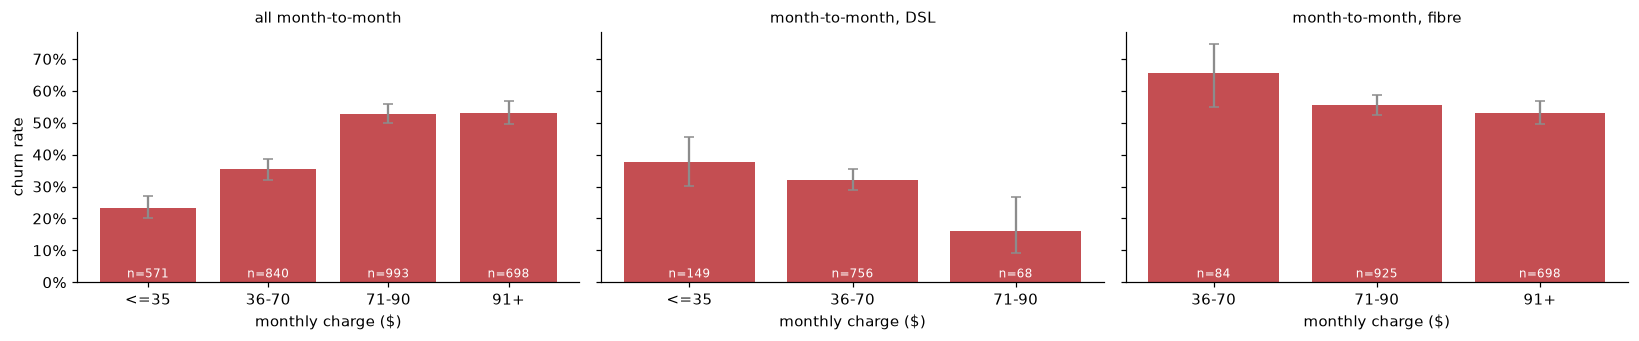

InternetService
DSL            56.15
Fiber optic    92.45
No             20.15


In [5]:
m2m = train[train["Contract"] == "Month-to-month"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for ax, (title, subset) in zip(
    axes,
    [("all month-to-month", m2m), ("month-to-month, DSL", m2m[m2m["InternetService"] == "DSL"]), ("month-to-month, fibre", m2m[m2m["InternetService"] == "Fiber optic"])],
    strict=True,
):
    t = eda.rate_table(subset, "MonthlyCharges", eda.CHARGE_BINS, eda.CHARGE_LABELS)
    ax.bar(t.index.astype(str), t["rate"], color=ACCENT)
    ax.errorbar(t.index.astype(str), t["rate"], yerr=[t["rate"] - t["lo"], t["hi"] - t["rate"]], fmt="none", ecolor=GREY, capsize=3)
    for x, n in enumerate(t["n"]):
        ax.text(x, 0.015, f"n={n}", ha="center", fontsize=8, color="white")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("monthly charge ($)")
axes[0].set_ylabel("churn rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
plt.show()
print(train.groupby("InternetService")["MonthlyCharges"].median().to_string())

Among all month-to-month customers, churn climbs with the monthly bill (23.3% at $35 or less, 52.9% to 53.2% above $70). That looks like a price effect, but split by service it is not: within DSL, churn *falls* as the bill rises (37.6%, 32.0%, 16.2%), and within fibre it is flat or falling (65.5% at $36-70, 55.6% at $71-90, 53.2% above $90; the first fibre bar has only 84 customers). The overall rise happens because fibre customers pay more (median $92.45 against $56.15 for DSL) and churn more. **Monthly charges look like a stand-in for service type here, not an independent price signal.** A model will use it, but it should not be read as "raise prices and churn rises".

### 4c. Electronic check against contract type

In [6]:
print(eda.rate_table(m2m, "PaymentMethod")[["n", "rate"]].round(3).to_string())
print()
print("share on month-to-month:", train.groupby("PaymentMethod")["Contract"].apply(lambda s: (s == "Month-to-month").mean()).round(3).to_dict())

                              n   rate
PaymentMethod                         
Bank transfer (automatic)   476  0.330
Credit card (automatic)     425  0.322
Electronic check           1484  0.542
Mailed check                717  0.317

share on month-to-month: {'Bank transfer (automatic)': 0.383, 'Credit card (automatic)': 0.35, 'Electronic check': 0.785, 'Mailed check': 0.558}


78.5% of electronic-check customers are on month-to-month contracts (35% to 56% for the other methods), so part of its 45.7% churn is the contract. But within month-to-month customers alone, electronic-check users still churn at 54.2% against 31.7% to 33.0% for the others. Payment method carries signal beyond contract type, although this is still an association: people who pay by electronic check may differ in other ways.

## 5. What does *not* matter

In [7]:
for col in ["gender", "PhoneService", "SeniorCitizen"]:
    print(eda.rate_table(train, col)[["n", "rate"]].round(3).to_string(), "\n")

           n   rate
gender             
Female  2801  0.266
Male    2833  0.264 

                 n   rate
PhoneService             
No             559  0.242
Yes           5075  0.268 

                  n   rate
SeniorCitizen             
0              4714  0.237
1               920  0.411 



Gender is irrelevant to churn here (26.6% for women, 26.4% for men), which is also what a fair model should reflect. Having phone service makes almost no difference (26.8% with, 24.2% without). Senior citizens are a real exception: 41.1% churn against 23.7%, which matters for the fairness checks planned later because it is a protected group with a genuinely different base rate.

## 6. Ranking every feature by association with churn

Cramér's V (0 = unrelated, 1 = perfectly related) on one scale for all 19 inputs; numeric columns are cut into quintiles first. It is a screening tool: it ignores interactions and says nothing about causes.

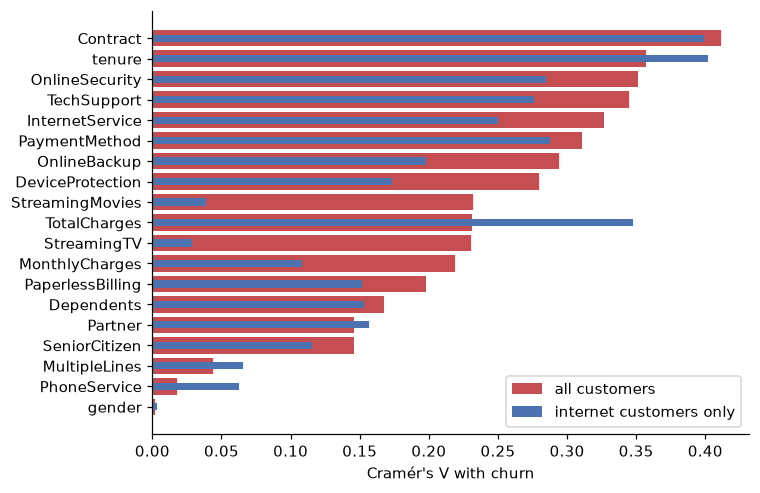

,feature,cramers_v,among_internet_customers
0,Contract,0.411,0.399
1,tenure,0.357,0.402
2,OnlineSecurity,0.351,0.285
3,TechSupport,0.345,0.276
4,InternetService,0.327,0.249
5,PaymentMethod,0.311,0.287
6,OnlineBackup,0.294,0.198
7,DeviceProtection,0.280,0.172


In [8]:
rank = eda.association_ranking(train)
internet_only = eda.association_ranking(train[train["InternetService"] != "No"]).set_index("feature")["cramers_v"]
rank["among_internet_customers"] = rank["feature"].map(internet_only)

fig, ax = plt.subplots(figsize=(7, 5))
ordered = rank.iloc[::-1]
ax.barh(ordered["feature"], ordered["cramers_v"], color=ACCENT, label="all customers")
ax.barh(ordered["feature"], ordered["among_internet_customers"].fillna(0), color="#4c72b0", height=0.35, label="internet customers only")
ax.set_xlabel("Cramér's V with churn")
ax.legend(loc="lower right")
plt.show()
rank.round(3).head(8)

- **Strongest:** Contract (0.41), tenure (0.36), online security (0.35), tech support (0.34), internet service (0.33), payment method (0.31).
- **Add-on columns are partly the "has internet" flag.** Streaming TV and streaming movies score 0.23 over all customers but only 0.03 to 0.04 among internet customers: on their own they say almost nothing beyond "this customer has internet". Online security and tech support are different: among internet customers they still score about 0.28 each, with churn at 41.9% without online security against 14.4% with it, and 41.8% without tech support against 15.2% with it. (Customers who add support services may be more engaged to begin with; this does not show that offering the service reduces churn.)
- **`TotalCharges` is the odd one:** 0.23 overall but 0.35 among internet customers. That fits it being mostly tenure times price (see the data card), so it should be treated as largely redundant with tenure.
- **Near zero:** gender (0.002), phone service (0.018), multiple lines (0.044).

## 7. Findings and what they mean for modelling

| Finding | Evidence | Modelling implication |
|---|---|---|
| Contract type is the strongest single signal | 42.7% / 11.1% / 2.9% churn | Keep as a categorical feature; expect any model to use it first |
| Risk is concentrated in the first year | 55% of churners leave within 12 months | Tenure needs a flexible treatment (bins or splines); a straight line will fit it poorly |
| Fibre churn is not explained by contract | Gap persists in all three contract types | Include internet service; consider an interaction with contract |
| Monthly charges mostly proxy service type | Falls with price within DSL, flat within fibre | Do not interpret its coefficient as a price effect |
| Payment method adds signal beyond contract | Electronic check 54.2% vs about 32% within month-to-month | Keep; check the feature stays useful once contract is in |
| Streaming add-ons carry little beyond "has internet" | V falls from 0.23 to 0.03 | Candidates to drop or merge; the preprocessing stage tests this |
| Gender carries no signal; seniors differ | 26.6% vs 26.4%; 41.1% vs 23.7% | Exclude gender from the model inputs; audit results by senior status |

**Limits.** All of this is observational and from one sample dataset: nothing here shows that changing a contract, a price or a payment method would change churn. Group sizes are large, but the rates come from a single stratified split, so the second decimal should not be trusted.